# 🤖 ChatGPT Review Analysis
### Sentiment analysis & feature extraction on ~197K Google Play reviews

**Course:** Crio DA-201 · **Tool:** Python (pandas, TextBlob, scikit-learn, matplotlib, seaborn, WordCloud)

---

## 📑 Contents

| # | Section | What you will see |
|---|---------|-------------------|
| 1 | Problem framing | Problem statement, why it matters, business question, hypotheses |
| 2 | Setup | Libraries, configuration, loading the data (works locally and in Google Colab) |
| 3 | Data understanding | Size, columns, types, missing values, first look |
| 4 | Data preparation | Cleaning log: rename, nulls, types, duplicates, text cleaning |
| 5 | Exploratory data analysis | Ratings, volume over time, review length |
| 6 | Sentiment analysis | Polarity, subjectivity, labels, sentiment vs. rating |
| 7 | Text analysis | Keywords & phrases users praise (and criticise), word clouds, feature mentions |
| 8 | Insights & recommendations | Answers to the business question, limitations, next steps |

> 💡 **How to read this notebook:** every code block is preceded by a short **"Why"** note and followed by a
> **"What we see"** note, so the story can be followed without reading the code.

---
# 1️⃣ Problem Framing & Objective

## 🎯 Problem statement
ChatGPT is one of the most widely used AI apps in the world. Hundreds of thousands of users have left
free-text reviews and a 1–5 star rating on the Google Play Store. A star rating tells us *how much* a user
liked the app, but **not why**. The review text holds the "why" — but nobody can read 197,000 reviews by hand.

## 🌍 Why this matters
* **Product teams** need to know which features delight users and which cause frustration, to prioritise the roadmap.
* **Support / operations teams** need to spot recurring complaints (errors, limits, login problems) early.
* **Marketing teams** can reuse the exact words happy users use to describe the product.

## ❓ Business question
> **What do users feel about ChatGPT, how strongly do they feel it, and which specific features or aspects do they most often praise or criticise?**

This breaks down into three measurable sub-questions:

| # | Sub-question | Method |
|---|--------------|--------|
| Q1 | What is the **general sentiment** users express? | Sentiment *polarity* (−1 negative … +1 positive) → Positive / Neutral / Negative |
| Q2 | How **strong / opinionated** is that sentiment? | Sentiment *subjectivity* (0 factual … 1 opinion) |
| Q3 | Which **features or aspects** are praised or criticised? | Keyword & phrase frequency, word clouds, aspect mention rates |

## 🧪 Hypotheses (tested later)
* **H1:** The star rating and the text sentiment broadly agree (higher stars → higher polarity).
* **H2:** Praise is about *what ChatGPT does* (answers, help, coding, learning), while criticism is about
  *access and reliability* (errors, limits, paywall, login) — not the quality of the AI itself.
* **H3:** A small share of reviews will *disagree* with their own stars (e.g. "great app" with 1 star),
  which is a data-quality caveat any rating-only analysis would miss.

---
# 2️⃣ Setup

## 2.1 Install & import libraries
**Why:** Google Colab does not ship with `textblob` and `wordcloud`; `%pip install` adds them (it is a harmless no-op locally
if they are already installed).

| Library | Role in this project |
|---------|----------------------|
| `pandas`, `numpy` | Load, clean and aggregate the data |
| `TextBlob` | Rule-based sentiment: gives **polarity** and **subjectivity** per review |
| `scikit-learn` `CountVectorizer` | Fast word / phrase (n-gram) counting |
| `nltk` | English stop-word list (words like *the, is, and* that carry no meaning) |
| `matplotlib`, `seaborn`, `wordcloud` | Visualisation |

In [1]:
# %pip install -q textblob wordcloud nltk seaborn scikit-learn

In [2]:
# ---- Standard library ----
import os
import re
import sys
import time
import warnings
from collections import Counter

# ---- Data & numerics ----
import numpy as np
import pandas as pd

# ---- NLP ----
import nltk
from textblob import TextBlob
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer

# ---- Visualisation ----
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# NLTK data: stop-word list (TextBlob's tokenizer data is fetched on demand as well)
for pkg in ["stopwords", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.12.7 | pandas 3.0.5 | numpy 1.26.4


## 2.2 Configuration
**Why:** Every "magic number" lives in one place. If the thresholds are questioned in the demo, they can be changed here and the whole notebook re-run.

* **Neutral band ±0.05** – TextBlob returns exactly `0.0` for text it has no opinion words for. A small band around zero keeps
  "neutral" meaning *no clear sentiment* rather than *slightly positive*. (±0.05 is the same convention widely used with VADER.)
* **Positive reviews = 4–5 ★, Critical reviews = 1–2 ★** – the user's own star rating is the most reliable label we have; 3★ is treated as mixed.
* **`SAMPLE_SIZE`** – leave as `None` to analyse everything. Set e.g. `50_000` if the notebook feels slow in Colab.

In [3]:
# ---------------------------- CONFIGURATION ----------------------------
SAMPLE_SIZE = None       # None = use all reviews; or an int (e.g. 50_000) for a faster run
SEED = 42                # reproducibility for any random sampling

POS_THRESHOLD = 0.05     # polarity >  +0.05  -> "Positive"
NEG_THRESHOLD = -0.05    # polarity <  -0.05  -> "Negative"  (in between -> "Neutral")

POSITIVE_MIN_RATING = 4  # rating >= 4 counts as a "positively rated" review
NEGATIVE_MAX_RATING = 2  # rating <= 2 counts as a "critical" review

TOP_N = 20               # how many keywords / phrases to show in charts

DATA_FILE = "chatgpt_reviews.csv"

# ---------------------------- STYLE ----------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

SENT_COLORS = {"Positive": "#2E9E5B", "Neutral": "#9AA0A6", "Negative": "#D64545"}
SENT_ORDER = ["Positive", "Neutral", "Negative"]
BLUE = "#3B6FB6"

## 2.3 Load the data
**Why:** The loader first looks for the CSV next to the notebook (local use). If it is not found and we are in **Google Colab**,
it opens an upload dialog so the file can be chosen from the computer. (Alternative: mount Google Drive and put the path in `DATA_FILE`.)

In [4]:
def locate_data(filename):
    """Return a path to the dataset, asking for an upload when running in Google Colab."""
    candidates = [filename, os.path.join("/content", filename),
                  os.path.join("/content/drive/MyDrive", filename)]
    for path in candidates:
        if os.path.exists(path):
            return path
    if "google.colab" in sys.modules:                     # running inside Colab
        from google.colab import files
        print(f"'{filename}' not found - please choose the file to upload...")
        uploaded = files.upload()
        return next(iter(uploaded))
    raise FileNotFoundError(f"Place '{filename}' in the same folder as this notebook.")


raw = pd.read_csv(locate_data(DATA_FILE))
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns")

Loaded 196,727 rows x 4 columns


---
# 3️⃣ Data Understanding

## 3.1 Dataset overview
**Source:** Public Google Play Store reviews of the ChatGPT Android app (provided as `chatgpt_reviews.csv`).
**Grain:** one row = one review.

| Column | Meaning | Expected type |
|--------|---------|---------------|
| `Review Id` | Unique identifier of the review | text |
| `Review` | Free-text written by the user | text |
| `Ratings` | Star rating given, 1 (worst) – 5 (best) | integer |
| `Review Date` | Timestamp when the review was posted | datetime |

**Why look first:** before changing anything we need to know what is wrong with the data — otherwise we cannot justify our cleaning steps.

In [5]:
print("Shape:", raw.shape)
display(raw.head(8))
print("\nData types / non-null counts:")
raw.info()

Shape: (196727, 4)


,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39
5,9cdc3f78-15cd-4e9d-9287-31bc5af496c4,so nice app,5,2024-08-23 19:18:35
6,3c26ee92-4d72-45ee-9242-caab930903ca,"just love this app, or guy",4,2024-08-23 19:14:40
7,f293ed19-688a-42e2-8282-ddd077771a94,great app,1,2024-08-23 19:12:00



Data types / non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 196727 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   Review Id    196727 non-null  str  
 1   Review       196721 non-null  str  
 2   Ratings      196727 non-null  int64
 3   Review Date  196727 non-null  str  
dtypes: int64(1), str(3)
memory usage: 6.0 MB


In [6]:
# Quick health check: missing values, duplicates and the value ranges
health = pd.DataFrame({
    "missing_values": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(3),
    "unique_values": raw.nunique(),
})
display(health)

print(f"Duplicate Review Ids        : {raw['Review Id'].duplicated().sum():,}")
print(f"Rating values present       : {sorted(raw['Ratings'].unique())}")
print(f"Date range                  : {raw['Review Date'].min()}  ->  {raw['Review Date'].max()}")

,missing_values,missing_%,unique_values
Review Id,0,0.000,193154
Review,6,0.003,125495
Ratings,0,0.000,5
Review Date,0,0.000,192689


Duplicate Review Ids        : 3,573
Rating values present       : [1, 2, 3, 4, 5]
Date range                  : 2023-07-25 15:01:35  ->  2024-08-23 19:30:05


### 👀 What we see
* ~197K reviews, 4 columns. Only **6 reviews are missing text** and no ratings/dates are missing — a very clean file at first sight.
* `Review Id` is meant to be unique, but **thousands of IDs repeat** → duplicate rows to remove.
* `Review Date` is stored as plain text → must be converted to a real date type.
* Ratings are on a 1–5 scale, as expected.

---
# 4️⃣ Data Preparation

Each step below is **logged** (rows before → after) so the effect of every decision is visible and auditable.

| Step | Action | Justification |
|------|--------|---------------|
| 1 | Standardise column names | `snake_case` names are easier to type and avoid errors with spaces |
| 2 | Fill missing reviews with an empty string | Avoids `NaN` crashing text functions |
| 3 | Convert types (rating → int, date → datetime) | Needed for maths and time-series grouping |
| 4 | Drop duplicate `review_id`s | The ID is a unique key; a repeated ID is the same review scraped twice and would double-count it |
| 5 | Drop reviews with no text | Nothing to analyse for sentiment or keywords |
| 6 | Create helper columns (length, month, clean text) | Features for EDA and NLP |

> ⚠️ **Decision – duplicate *text* is kept.** About a third of rows share identical text and rating with another row
> (e.g. thousands of separate users wrote just `"good"`). These are **different users** with different IDs, so they are legitimate votes and removing them would
> understate how common short praise is. Only repeated **IDs** are removed.

In [7]:
df = raw.copy()
cleaning_log = [("Raw data loaded", len(df))]

# STEP 1 - standardise column names: lower-case, spaces -> underscores, "Ratings" -> "rating"
df.columns = (df.columns.str.strip().str.lower().str.replace(" ", "_"))
df = df.rename(columns={"ratings": "rating"})
print("Columns now:", list(df.columns))

# STEP 2 - missing review text -> empty string
n_missing = df["review"].isna().sum()
df["review"] = df["review"].fillna("").astype(str)
print(f"Filled {n_missing} missing reviews with an empty string")

# STEP 3 - correct data types
df["rating"] = pd.to_numeric(df["rating"], errors="coerce").astype("Int64")
df["review_date"] = pd.to_datetime(df["review_date"], errors="coerce")
print("Unparseable ratings:", df["rating"].isna().sum(), "| Unparseable dates:", df["review_date"].isna().sum())

# STEP 4 - drop duplicate review ids (keep the first occurrence)
df = df.drop_duplicates(subset="review_id", keep="first")
cleaning_log.append(("After dropping duplicate review_id", len(df)))

# STEP 5 - drop reviews with no text at all
df = df[df["review"].str.strip() != ""]
cleaning_log.append(("After dropping empty reviews", len(df)))

# Optional: down-sample for speed (off by default)
if SAMPLE_SIZE:
    df = df.sample(SAMPLE_SIZE, random_state=SEED)
    cleaning_log.append((f"After sampling {SAMPLE_SIZE:,} rows", len(df)))

df = df.reset_index(drop=True)

log = pd.DataFrame(cleaning_log, columns=["step", "rows"])
log["rows_removed"] = (-log["rows"].diff()).fillna(0).astype(int)
display(log)

Columns now: ['review_id', 'review', 'rating', 'review_date']
Filled 6 missing reviews with an empty string
Unparseable ratings: 0 | Unparseable dates: 0


,step,rows,rows_removed
0,Raw data loaded,196727,0
1,After dropping duplicate review_id,193154,3573
2,After dropping empty reviews,193148,6


## 4.1 Feature engineering
**Why:** These helper columns power the EDA and NLP sections.

* `review_length` / `word_count` – do critical users write more than happy ones?
* `review_month` – to see volume and satisfaction over time.
* `is_ascii` – a cheap flag for **non-English / emoji** reviews. TextBlob only understands English, so we will later check how this affects the results.
* `clean_review` – lower-cased text with URLs, digits, punctuation and emojis removed. Used **only for keyword counting**.
  Sentiment is scored on the *original* text because TextBlob uses punctuation, capitalisation of intensifiers and negations (e.g. *"not good"*).

In [8]:
df["review_length"] = df["review"].str.len()
df["word_count"] = df["review"].str.split().str.len()
df["review_month"] = df["review_date"].dt.to_period("M").dt.to_timestamp()
df["is_ascii"] = df["review"].map(str.isascii)


def clean_text(text: str) -> str:
    """Lower-case, strip URLs and anything that is not a letter, collapse whitespace."""
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # URLs
    text = re.sub(r"[^a-z\s]", " ", text)            # digits, punctuation, emojis, non-English letters
    return re.sub(r"\s+", " ", text).strip()


df["clean_review"] = df["review"].map(clean_text)

display(df[["review", "clean_review", "rating", "review_date", "review_length", "word_count"]].sample(6, random_state=SEED))
print(f"\nFinal analysis dataset: {len(df):,} reviews")

,review,clean_review,rating,review_date,review_length,word_count
188933,Nice App😍,nice app,5,2023-07-25 15:16:23,9,2
125163,Simply the best no need for any other chat bot...,simply the best no need for any other chat bot...,5,2023-09-18 13:49:40,64,12
162291,Excelente,excelente,5,2024-04-09 07:24:10,9,1
47023,good,good,5,2024-06-28 15:30:13,4,1
134893,I can do any of my school assignments with it,i can do any of my school assignments with it,5,2024-04-30 13:57:59,45,10
14868,VERY Good apps,very good apps,5,2024-08-07 12:55:34,14,3



Final analysis dataset: 193,148 reviews


## 4.2 Outlier check on review length
**Why:** Extremely long or empty texts can distort averages. The box plot below shows the spread.

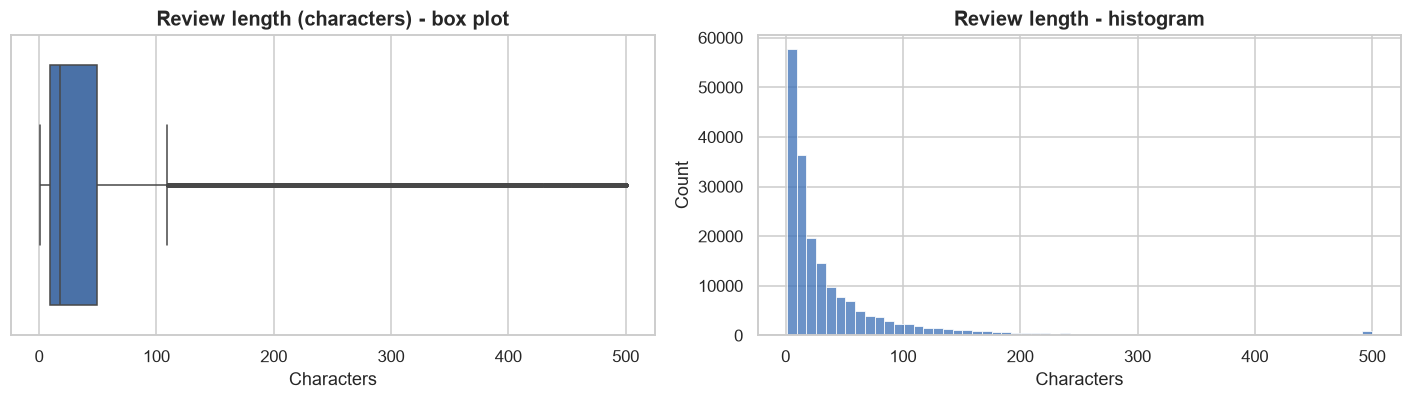

count    193148.0
mean         46.3
std          74.5
min           1.0
25%           9.0
50%          18.0
75%          49.0
max         500.0

Share of reviews at the 500-character cap: 0.1%


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))

sns.boxplot(x=df["review_length"], color=BLUE, ax=ax[0], fliersize=1.5)
ax[0].set_title("Review length (characters) - box plot")
ax[0].set_xlabel("Characters")

sns.histplot(df["review_length"], bins=60, color=BLUE, ax=ax[1])
ax[1].set_title("Review length - histogram")
ax[1].set_xlabel("Characters")
plt.tight_layout()
plt.show()

print(df["review_length"].describe().round(1).to_string())
print(f"\nShare of reviews at the 500-character cap: {(df['review_length'] >= 500).mean():.1%}")

### 👀 What we see – and the decision
* The **median review is only ~18 characters** (a few words); the long tail ends at **500 characters, which looks like the Play Store's maximum review length**.
* The "outliers" on the box plot are therefore just genuine, detailed reviews — not errors. **Decision: keep all of them.**
* Because most reviews are very short, a rule-based sentiment tool will have little text to work with — we keep this in mind when we interpret results.

---
# 5️⃣ Exploratory Data Analysis (EDA)

**Goal:** Understand the shape of the data before modelling, and note early insights that shape the analysis.

## 5.1 Rating distribution

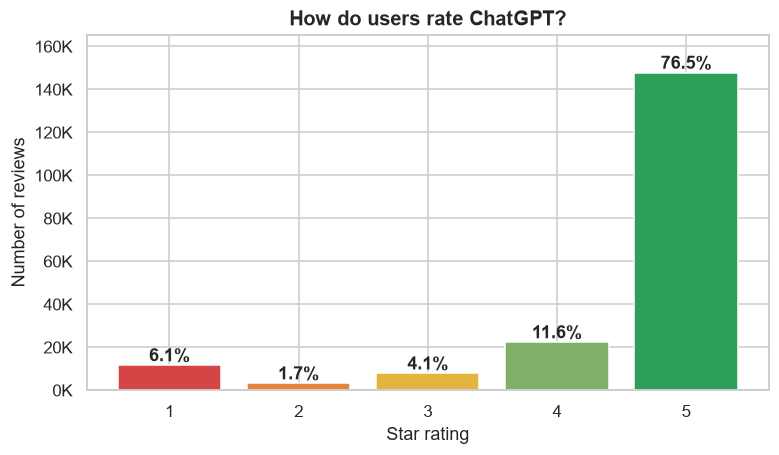

Average rating: 4.51 / 5   |   Median: 5


In [10]:
rating_counts = df["rating"].value_counts().sort_index()
rating_pct = rating_counts / rating_counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4.2))
palette = ["#D64545", "#E8833A", "#E3B43E", "#7FB069", "#2E9E5B"]
bars = ax.bar(rating_counts.index.astype(str), rating_counts.values, color=palette)
for bar, pct in zip(bars, rating_pct):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{pct:.1f}%", ha="center", va="bottom", fontweight="bold")
ax.set_title("How do users rate ChatGPT?")
ax.set_xlabel("Star rating")
ax.set_ylabel("Number of reviews")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}K"))
ax.set_ylim(0, rating_counts.max() * 1.12)
plt.show()

print(f"Average rating: {df['rating'].mean():.2f} / 5   |   Median: {df['rating'].median():.0f}")

### 👀 What we see
* A strongly **"J-shaped" distribution**: the vast majority of reviews are **5 stars**, followed by a small bump of 1-star reviews. The middle (2–3★) is thin.
* This is typical of app stores — people either love the app enough to rate it, or are annoyed enough to complain.
* 📌 **Early insight:** the *average* rating hides the polarisation. The text analysis must be done for happy and unhappy users **separately**.

## 5.2 Review volume and average rating over time
**Why:** Did satisfaction change as the app grew? The first and last months are *partial* months (the data starts on 25 July 2023 and ends on 23 Aug 2024), so they are shaded as a caution.

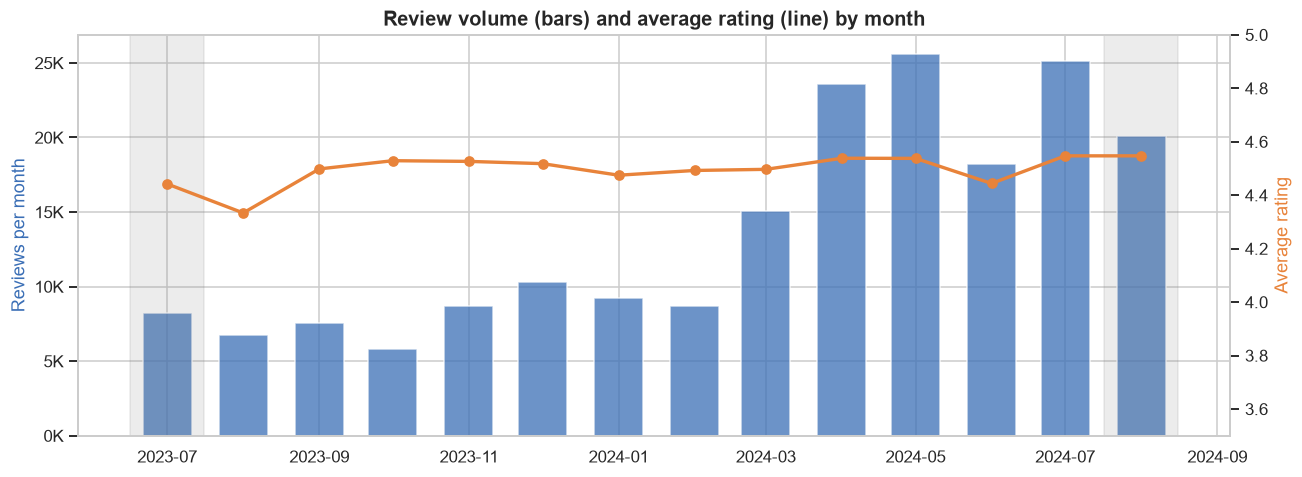

review_month,2023-07-01,2023-08-01,2023-09-01,2023-10-01,2023-11-01,2023-12-01,2024-01-01,2024-02-01,2024-03-01,2024-04-01,2024-05-01,2024-06-01,2024-07-01,2024-08-01
reviews,8254,6775,7565,5799,8684,10320,9265,8693,15078,23621,25609,18221,25141,20123
avg_rating,4.44,4.33,4.5,4.53,4.53,4.52,4.47,4.49,4.5,4.54,4.54,4.44,4.55,4.55


In [11]:
monthly = (df.groupby("review_month")
             .agg(reviews=("review_id", "count"), avg_rating=("rating", "mean"))
             .reset_index())

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(monthly["review_month"], monthly["reviews"], width=20, color=BLUE, alpha=0.75, label="Reviews")
ax1.set_ylabel("Reviews per month", color=BLUE)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}K"))

ax2 = ax1.twinx()
ax2.plot(monthly["review_month"], monthly["avg_rating"], color="#E8833A", marker="o", linewidth=2.2, label="Avg rating")
ax2.set_ylabel("Average rating", color="#E8833A")
ax2.set_ylim(3.5, 5)
ax2.grid(False)

for edge in (monthly["review_month"].iloc[0], monthly["review_month"].iloc[-1]):   # partial months
    ax1.axvspan(edge - pd.Timedelta(days=15), edge + pd.Timedelta(days=15), color="grey", alpha=0.15)

ax1.set_title("Review volume (bars) and average rating (line) by month")
plt.tight_layout()
plt.show()

display(monthly.assign(avg_rating=monthly["avg_rating"].round(2)).set_index("review_month").T)

### 👀 What we see
* Review volume **roughly tripled from March–April 2024 onwards** (from ~6–10K reviews a month to ~18–25K). This is plausibly linked to product launches / media attention, but this dataset cannot confirm the cause.
* The average rating stays in a **narrow, high band (about 4.3–4.6)** in every month, so **time alone does not explain dissatisfaction**; the reasons must be in the text.

## 5.3 Do unhappy users write more?
**Why:** If critical users write longer reviews, their text is richer for analysis — and any word-count bias in sentiment needs explaining.

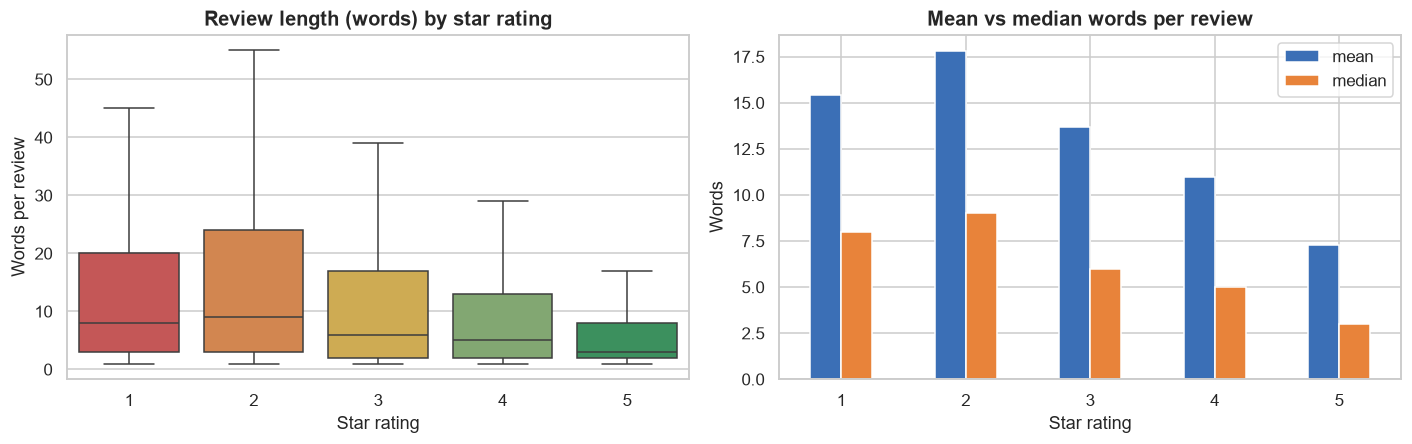

rating,1,2,3,4,5
mean,15.4,17.8,13.7,11.0,7.3
median,8.0,9.0,6.0,5.0,3.0


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

sns.boxplot(data=df, x="rating", y="word_count", palette=palette, ax=ax[0], showfliers=False)
ax[0].set_title("Review length (words) by star rating")
ax[0].set_xlabel("Star rating"); ax[0].set_ylabel("Words per review")

len_by_rating = df.groupby("rating")["word_count"].agg(["mean", "median"]).round(1)
len_by_rating.plot(kind="bar", ax=ax[1], color=[BLUE, "#E8833A"], rot=0)
ax[1].set_title("Mean vs median words per review")
ax[1].set_xlabel("Star rating"); ax[1].set_ylabel("Words")
plt.tight_layout()
plt.show()
display(len_by_rating.T)

### 👀 What we see
* **Low-star reviews are longer** (more words) than 5-star reviews. Happy users say *"good"*, *"nice app"*; unhappy users explain *what went wrong*.
* 📌 **Early insight that shapes the analysis:** critical reviews are fewer but **information-rich** — so we will mine them separately for the specific problems, not just count them.

---
# 6️⃣ Sentiment Analysis

## 6.1 Method: TextBlob polarity & subjectivity
**What it is:** TextBlob uses a *lexicon* (dictionary) of English adjectives, each with a pre-assigned polarity and subjectivity (e.g. *"great"* = +0.8 polarity, *"terrible"* = −1.0).
It averages the words in a review and handles simple modifiers (*"very"*) and negation (*"not"*).

| Output | Range | Meaning |
|--------|-------|---------|
| **Polarity** | −1.0 … +1.0 | −1 very negative · 0 neutral · +1 very positive |
| **Subjectivity** | 0.0 … 1.0 | 0 objective fact · 1 personal opinion / emotion |

**Why TextBlob (not a deep-learning model)?**
1. The brief asks for *both* polarity **and** subjectivity — TextBlob provides both out of the box (VADER only gives polarity).
2. It is fast and runs on ~190K reviews in about a minute on a normal CPU — no GPU needed.
3. It is **transparent**: any score can be explained word by word, which is ideal for a business audience.
4. Its limits (sarcasm, non-English, very short text) are well known, and we measure them in section 6.5.

**Label rule:** polarity > +0.05 → **Positive**, < −0.05 → **Negative**, otherwise **Neutral**.

Let's first see it work on three examples:

In [13]:
examples = ["This is a great app, so helpful for my studies!",
            "It stops midway and asks me to upgrade. Very disappointing.",
            "I use it every day."]
for text in examples:
    s = TextBlob(text).sentiment
    print(f"polarity={s.polarity:+.2f}  subjectivity={s.subjectivity:.2f}  <-  {text}")

polarity=+1.00  subjectivity=0.75  <-  This is a great app, so helpful for my studies!
polarity=-0.78  subjectivity=0.91  <-  It stops midway and asks me to upgrade. Very disappointing.
polarity=+0.00  subjectivity=0.00  <-  I use it every day.


## 6.2 Score every review
**Why:** We run TextBlob on the *original* review text (not the cleaned one) because punctuation and negations matter for scoring.

In [14]:
def score(text: str):
    s = TextBlob(text).sentiment
    return s.polarity, s.subjectivity


t0 = time.time()
scores = df["review"].map(score)
df["polarity"] = scores.str[0]
df["subjectivity"] = scores.str[1]
print(f"Scored {len(df):,} reviews in {time.time() - t0:.0f} seconds")


def label_sentiment(p: float) -> str:
    if p > POS_THRESHOLD:
        return "Positive"
    if p < NEG_THRESHOLD:
        return "Negative"
    return "Neutral"


df["sentiment"] = df["polarity"].map(label_sentiment)
df["sentiment"] = pd.Categorical(df["sentiment"], categories=SENT_ORDER, ordered=True)

display(df[["review", "rating", "polarity", "subjectivity", "sentiment"]].sample(8, random_state=SEED))

Scored 193,148 reviews in 45 seconds


,review,rating,polarity,subjectivity,sentiment
188933,Nice App😍,5,0.600000,1.000000,Positive
125163,Simply the best no need for any other chat bot...,5,0.268229,0.344048,Positive
162291,Excelente,5,0.000000,0.000000,Neutral
47023,good,5,0.700000,0.600000,Positive
134893,I can do any of my school assignments with it,5,0.000000,0.000000,Neutral
14868,VERY Good apps,5,0.910000,0.780000,Positive
105931,ChaatGPT is an outstanding app.It gives good i...,5,0.497917,0.639583,Positive
24792,no given mind blowing song,1,0.000000,0.000000,Neutral


## 6.3 General sentiment (Q1) – polarity distribution

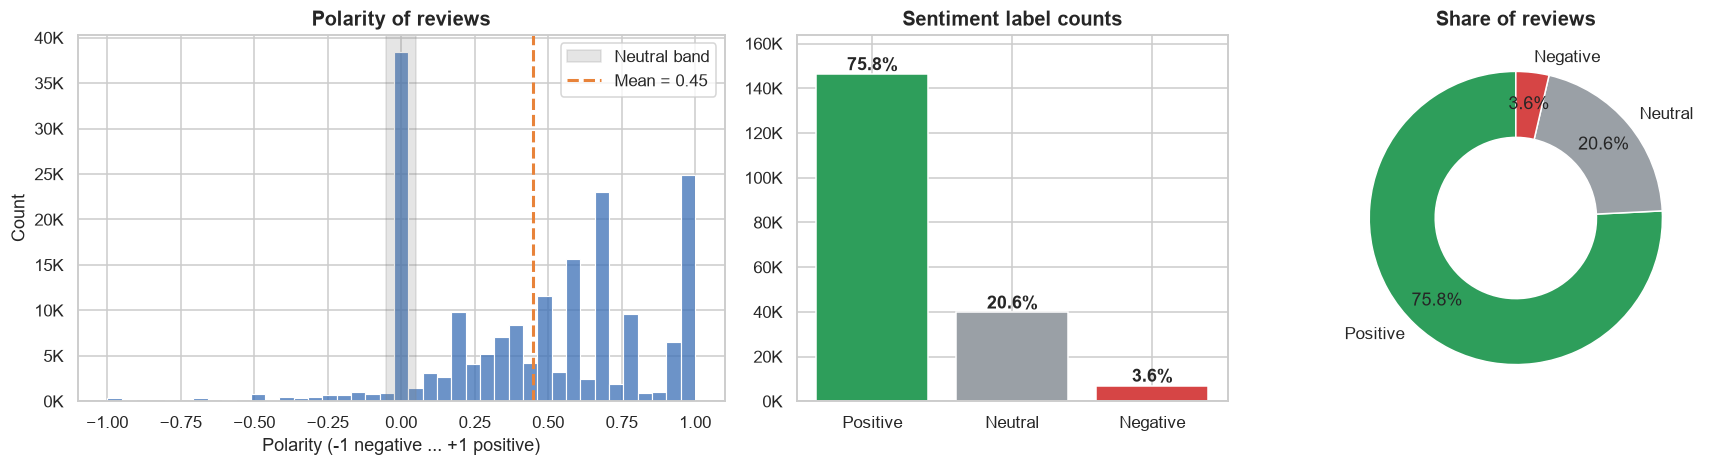

Mean polarity: 0.448 | Median: 0.500


In [15]:
sent_counts = df["sentiment"].value_counts().reindex(SENT_ORDER)
sent_pct = sent_counts / sent_counts.sum() * 100

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1.5, 1, 1]})

# (a) polarity histogram
sns.histplot(df["polarity"], bins=41, color=BLUE, ax=ax[0])
ax[0].axvspan(NEG_THRESHOLD, POS_THRESHOLD, color="grey", alpha=0.2, label="Neutral band")
ax[0].axvline(df["polarity"].mean(), color="#E8833A", linestyle="--", linewidth=2, label=f"Mean = {df['polarity'].mean():.2f}")
ax[0].set_title("Polarity of reviews"); ax[0].set_xlabel("Polarity (-1 negative ... +1 positive)"); ax[0].legend()
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}K"))

# (b) label counts
bars = ax[1].bar(SENT_ORDER, sent_counts.values, color=[SENT_COLORS[s] for s in SENT_ORDER])
for b, p in zip(bars, sent_pct):
    ax[1].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{p:.1f}%", ha="center", va="bottom", fontweight="bold")
ax[1].set_title("Sentiment label counts"); ax[1].set_ylim(0, sent_counts.max() * 1.12)
ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}K"))

# (c) share donut
ax[2].pie(sent_counts.values, labels=SENT_ORDER, colors=[SENT_COLORS[s] for s in SENT_ORDER],
          autopct="%1.1f%%", startangle=90, wedgeprops={"width": 0.45, "edgecolor": "white"}, pctdistance=0.78)
ax[2].set_title("Share of reviews")
plt.tight_layout()
plt.show()

print(f"Mean polarity: {df['polarity'].mean():.3f} | Median: {df['polarity'].median():.3f}")

### 👀 What we see
* Sentiment is **overwhelmingly positive**; negative reviews are a small minority. **Answer to Q1: users like ChatGPT.**
* A noticeable block of reviews sits **exactly at 0 (neutral)** — texts with no opinion words TextBlob recognises: short factual-sounding statements, emoji-only or non-English reviews (non-English is quantified in section 6.5).

## 6.4 Strength of opinion (Q2) – subjectivity distribution

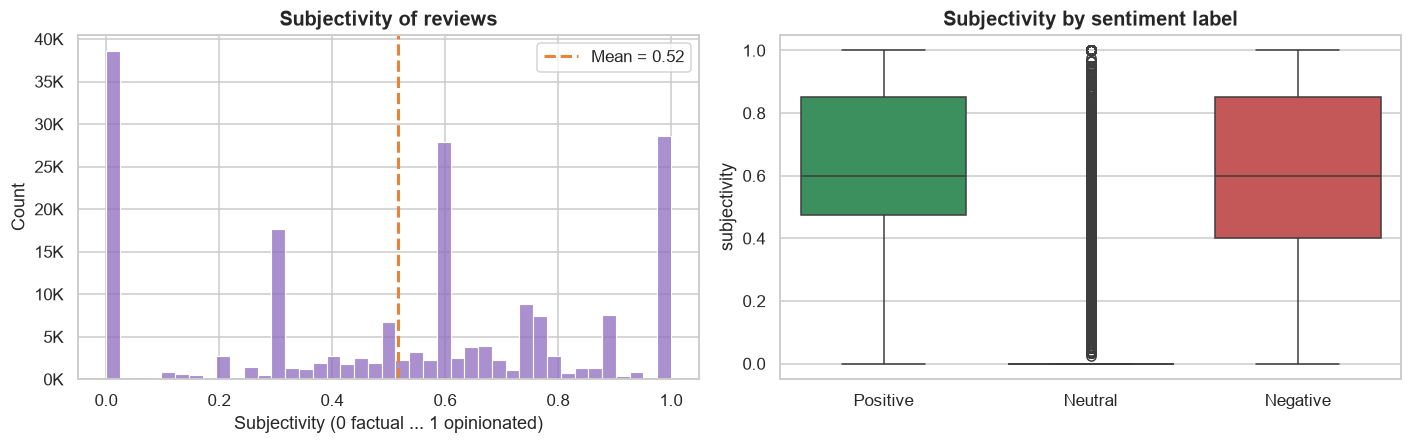

,mean,median,count
sentiment,,,
Positive,0.638,0.6,146360
Neutral,0.057,0.0,39758
Negative,0.605,0.6,7030


Reviews with subjectivity exactly 0 (no opinion words detected): 20.0%


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

sns.histplot(df["subjectivity"], bins=41, color="#8E6BBF", ax=ax[0])
ax[0].axvline(df["subjectivity"].mean(), color="#E8833A", linestyle="--", linewidth=2,
              label=f"Mean = {df['subjectivity'].mean():.2f}")
ax[0].set_title("Subjectivity of reviews"); ax[0].set_xlabel("Subjectivity (0 factual ... 1 opinionated)"); ax[0].legend()
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}K"))

sns.boxplot(data=df, x="sentiment", y="subjectivity", order=SENT_ORDER, palette=SENT_COLORS, ax=ax[1])
ax[1].set_title("Subjectivity by sentiment label"); ax[1].set_xlabel("")
plt.tight_layout()
plt.show()

subj_summary = df.groupby("sentiment", observed=True)["subjectivity"].agg(["mean", "median", "count"]).round(3)
display(subj_summary)
share_zero = (df["subjectivity"] == 0).mean()
print(f"Reviews with subjectivity exactly 0 (no opinion words detected): {share_zero:.1%}")

### 👀 What we see
* Among reviews where TextBlob finds opinion words, subjectivity is **high** — as expected for product reviews, which are personal opinions rather than facts.
* The spike at **0.0 subjectivity** is the same "no recognised opinion words" group as the neutral spike (e.g. *"ok"*, *"hi"*, emoji-only or non-English text).
* **Positive and negative reviews are both strongly opinionated** (subjectivity is similar for both) — **Answer to Q2: users feel strongly about the app in both directions**, rather than being detached.

## 6.5 Sentiment vs. star rating (testing H1)
**Why:** If TextBlob is a valid measure of satisfaction, its output should rise with the star rating. This is also the main *validation* of our method.

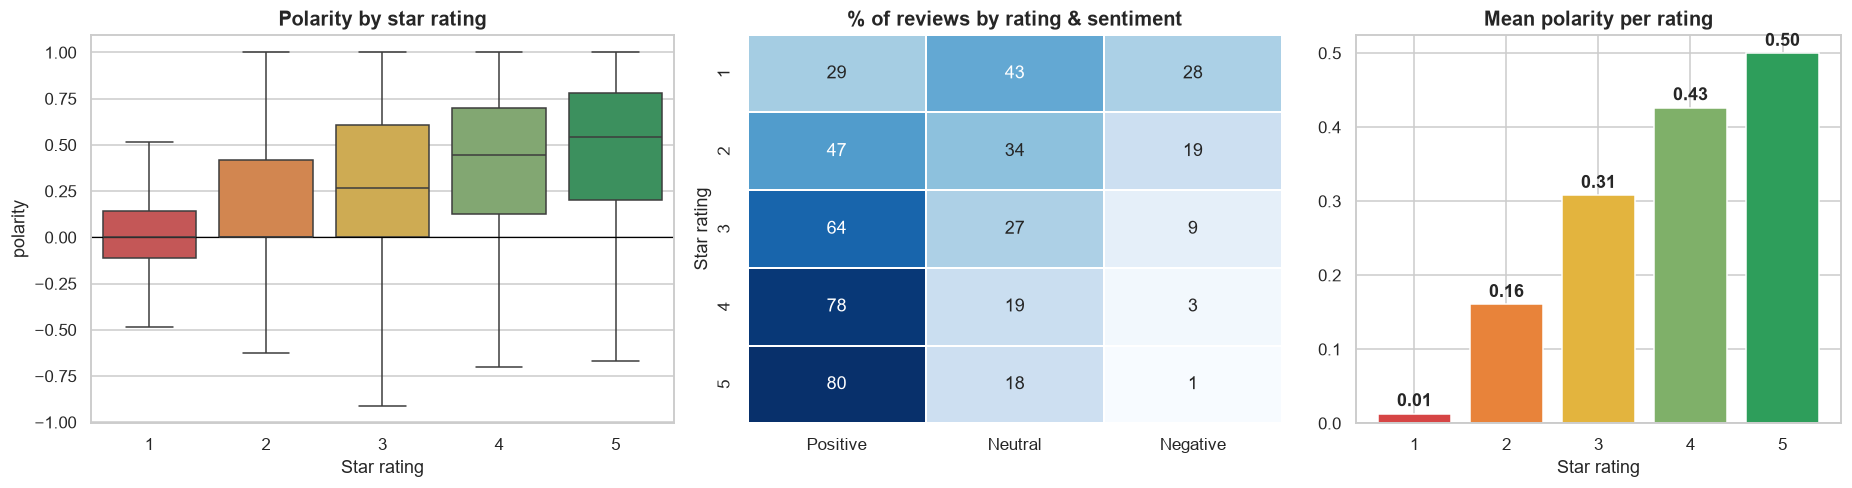

Spearman correlation between star rating and polarity: 0.25


In [17]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.2, 1.1, 1]})

# (a) polarity by rating
sns.boxplot(data=df, x="rating", y="polarity", palette=palette, ax=ax[0], showfliers=False)
ax[0].axhline(0, color="black", linewidth=0.8)
ax[0].set_title("Polarity by star rating"); ax[0].set_xlabel("Star rating")

# (b) % of each sentiment label within each rating
ct = pd.crosstab(df["rating"], df["sentiment"], normalize="index")[SENT_ORDER] * 100
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax[1], linewidths=1)
ax[1].set_title("% of reviews by rating & sentiment"); ax[1].set_xlabel(""); ax[1].set_ylabel("Star rating")

# (c) mean polarity per rating
mean_pol = df.groupby("rating")["polarity"].mean()
ax[2].bar(mean_pol.index.astype(str), mean_pol.values, color=palette)
ax[2].axhline(0, color="black", linewidth=0.8)
for i, v in enumerate(mean_pol.values):
    ax[2].text(i, v + (0.01 if v >= 0 else -0.03), f"{v:.2f}", ha="center", fontweight="bold")
ax[2].set_title("Mean polarity per rating"); ax[2].set_xlabel("Star rating")
plt.tight_layout()
plt.show()

corr = df[["rating", "polarity"]].astype(float).corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation between star rating and polarity: {corr:.2f}")

### 👀 What we see
* **H1 is supported:** mean polarity rises steadily from 1★ to 5★, and the heatmap shows the share of *Positive* reviews climbing with the rating while *Negative* shrinks.
* The relationship is clearly **positive but weak (Spearman ≈ 0.25)**. Two reasons: (1) most reviews are one or two words, so text carries little signal, and (2) low-star reviews are often *neutral* in wording — look at the 1★ row of the heatmap: only ~28% are Negative, ~29% are Positive and ~43% are Neutral.
* So TextBlob is a **useful but noisy** measure. The next two cells investigate where text and stars disagree.

### Mismatches (testing H3)
**Why:** Reviews where the text and stars *contradict* each other tell us how reliable each signal is. We look at:
1. **"Happy words, unhappy stars"** – 1–2★ reviews with clearly positive polarity (> +0.5).
2. **"Unhappy words, happy stars"** – 4–5★ reviews with clearly negative polarity (< −0.3).

In [18]:
low_but_positive = df[(df["rating"] <= NEGATIVE_MAX_RATING) & (df["polarity"] > 0.5)]
high_but_negative = df[(df["rating"] >= POSITIVE_MIN_RATING) & (df["polarity"] < -0.3)]

n_low = (df["rating"] <= NEGATIVE_MAX_RATING).sum()
n_high = (df["rating"] >= POSITIVE_MIN_RATING).sum()
print(f"1-2 star reviews with clearly POSITIVE text : {len(low_but_positive):>6,}  ({len(low_but_positive)/n_low:.1%} of all 1-2 star reviews)")
print(f"4-5 star reviews with clearly NEGATIVE text : {len(high_but_negative):>6,}  ({len(high_but_negative)/n_high:.1%} of all 4-5 star reviews)")

pd.set_option("display.max_colwidth", 140)
print("\n--- 1-2 stars but positive wording (random sample) ---")
display(low_but_positive[["review", "rating", "polarity"]].sample(6, random_state=SEED))
print("--- 4-5 stars but negative wording (random sample) ---")
display(high_but_negative[["review", "rating", "polarity"]].sample(6, random_state=SEED))

1-2 star reviews with clearly POSITIVE text :  1,969  (13.1% of all 1-2 star reviews)
4-5 star reviews with clearly NEGATIVE text :    863  (0.5% of all 4-5 star reviews)

--- 1-2 stars but positive wording (random sample) ---


,review,rating,polarity
59197,Nice,2,0.6
60450,Nott good,1,0.7
163141,good,1,0.7
129465,"0/5 needs Google Play services to run, could you devs please make it so that we non-gsf users still have access to this app? Thank you a...",1,0.6
116823,"I think this is a good app according to its responses,except that it does not allow pictorial questions",2,0.7
54206,good,1,0.7


--- 4-5 stars but negative wording (random sample) ---


,review,rating,polarity
149868,Insane !!!,5,-1.0
135591,it's kinda scary,4,-0.5
35207,It is awful,5,-1.0
59944,Some information provide wrong,4,-0.5
99377,I like to ask it questions it would be difficult for a person to answer and that I already know the answer to. I still haven't got an un...,5,-0.5
179056,insane,5,-1.0


### 👀 What we see
* **H3 is supported:** about **1 in 8 low-star (1–2★) reviews use clearly positive words**, while very few high-star reviews read as negative. Looking at the samples, the causes are:
  1. **Probable mis-taps** – *"good"* or *"Nice"* with 1★,
  2. **Mixed reviews** – praise followed by a complaint (*"good app… except that it does not allow pictorial questions"*, or *"0/5 needs Google Play services…"*),
  3. **Typos / negation the dictionary misses** – *"Nott good"* is read as positive because *"Nott"* is not recognised as a negation.
* On the other side, the 4–5★ reviews that read as negative are mostly **slang and amazement**: *"Insane!!!"*, *"it's kinda scary"* — the user is impressed, but the dictionary sees negative words. A few are real contradictions (*"Some information provide wrong"* with 4★).
* 📌 **Takeaway:** neither signal is perfect. Using *both* — star rating and text — is more trustworthy than either alone, which is why Section 7 builds its keyword lists from the star rating and uses sentiment as a cross-check.

### Limitation check: does TextBlob struggle with non-English / emoji reviews?
TextBlob's dictionary is English-only. We flagged non-ASCII reviews earlier (`is_ascii`) — let's quantify the damage.

In [19]:
check = (df.groupby("is_ascii")
           .agg(reviews=("review_id", "count"),
                avg_rating=("rating", "mean"),
                pct_neutral=("sentiment", lambda s: (s == "Neutral").mean() * 100),
                mean_polarity=("polarity", "mean"))
           .rename(index={True: "ASCII only (mostly English)", False: "Contains non-ASCII (emoji / other languages)"})
           .round(2))
display(check)

,reviews,avg_rating,pct_neutral,mean_polarity
is_ascii,,,,
Contains non-ASCII (emoji / other languages),33843,4.65,34.67,0.37
ASCII only (mostly English),159305,4.48,17.59,0.46


### 👀 What we see
Reviews containing non-ASCII characters are scored **Neutral about twice as often** (≈35% vs ≈18%) even though their star ratings are just as high (slightly higher, in fact). This is a **known limitation**, not a real effect:
the neutral group is inflated by text TextBlob cannot read. We keep these reviews in the analysis (their ratings are valid) but remember this when quoting the "Neutral %".

## 6.6 Sentiment over time
**Why:** Does the mood of the reviews change month to month? We plot the share of Positive and Negative reviews.

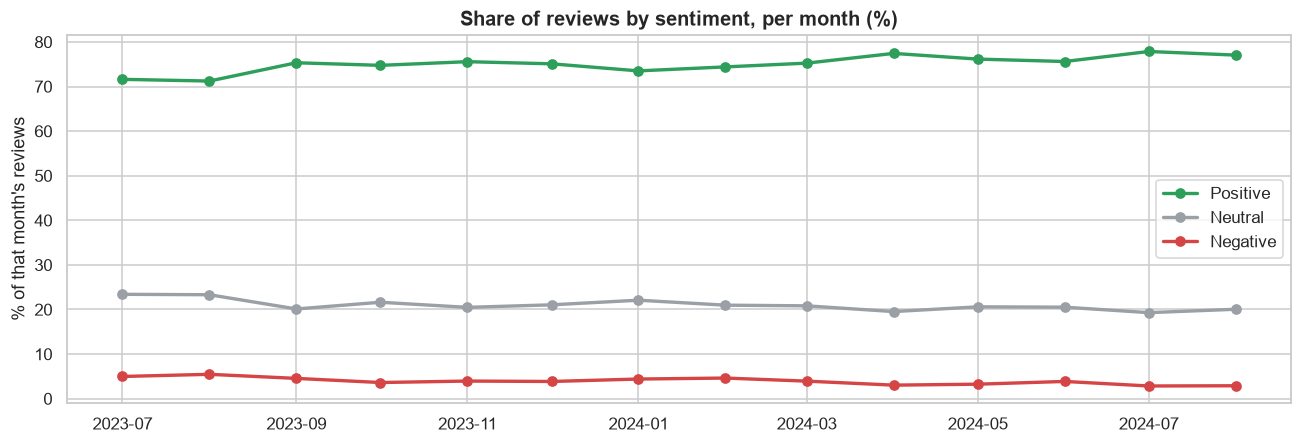

In [20]:
trend = (pd.crosstab(df["review_month"], df["sentiment"], normalize="index")[SENT_ORDER] * 100)

fig, ax = plt.subplots(figsize=(12, 4.2))
for s in SENT_ORDER:
    ax.plot(trend.index, trend[s], marker="o", linewidth=2.2, color=SENT_COLORS[s], label=s)
ax.set_title("Share of reviews by sentiment, per month (%)")
ax.set_ylabel("% of that month's reviews"); ax.legend()
plt.tight_layout()
plt.show()

### 👀 What we see
Positive reviews dominate **every month** and negative reviews are always a small slice. If anything, the mood **improves slightly**: the positive share edges up from ~71% (mid-2023) to ~77% (mid-2024) and the negative share falls from ~5% to under 3%.
There is no sign of a sentiment collapse, so the issues we find in Section 7 are *persistent, structural* complaints rather than a one-off incident.

---
# 7️⃣ Text Analysis – What do users praise (and criticise)?

## 7.1 Approach
1. **Filter:** *positively rated* reviews = **4–5★**; *critical* reviews = **1–2★**. (The star rating is the user's own explicit verdict — more reliable than an estimated polarity score, as Section 6.5 showed.)
2. **Remove stop-words:** common words (*the, and, is*) plus words that appear in almost every review but say nothing specific: *app, chatgpt, gpt, ai, openai…*. For two-word phrases we **keep negations** (*not, no*) so that *"not working"* stays distinct from *"working"*.
3. **Count:**
   * **Unigrams** (single words) → "what words come up?"
   * **Bigrams** (2-word phrases) → "in what context?" (*"easy use"*, *"customer support"* are far more informative than *"easy"*).
4. **Visualise** with bar charts (exact counts, good for comparison) and word clouds (instantly readable by a non-technical audience).

> 📝 Counts are **document frequency**-style: how often a term appears across reviews, which is robust to a few very long reviews.

In [21]:
# --- Stop-words: standard English list + domain words that carry no information here ---
DOMAIN_STOPWORDS = {"app", "apps", "chatgpt", "chat", "gpt", "openai", "ai", "really", "like", "just", "one",
                    "also", "even", "get", "got", "use", "using", "used", "would", "could", "much", "im", "ive",
                    "us", "ok", "okay", "thing", "things", "u", "ur", "dont", "cant", "don", "doesn", "didn"}
STOPWORDS = set(stopwords.words("english")) | DOMAIN_STOPWORDS
# For two-word phrases we KEEP negations, otherwise "not working" / "not good" collapse into "working" / "good"
NEGATIONS = {"not", "no", "nor", "never"}
STOPWORDS_FOR_PHRASES = STOPWORDS - NEGATIONS

positive_df = df[(df["rating"] >= POSITIVE_MIN_RATING) & (df["clean_review"] != "")]
critical_df = df[(df["rating"] <= NEGATIVE_MAX_RATING) & (df["clean_review"] != "")]
print(f"Positively rated reviews (4-5 stars): {len(positive_df):,}")
print(f"Critical reviews (1-2 stars)        : {len(critical_df):,}")


def top_terms(texts, ngram=(1, 1), top_n=TOP_N):
    """Return a DataFrame of the most frequent words / phrases (counted once per review)."""
    stops = STOPWORDS if ngram == (1, 1) else STOPWORDS_FOR_PHRASES
    vec = CountVectorizer(stop_words=list(stops), ngram_range=ngram, token_pattern=r"\b[a-z]{2,}\b", binary=True)
    matrix = vec.fit_transform(texts)
    counts = np.asarray(matrix.sum(axis=0)).ravel()
    terms = vec.get_feature_names_out()
    out = pd.DataFrame({"term": terms, "reviews": counts}).nlargest(top_n, "reviews")
    out["pct_of_reviews"] = (out["reviews"] / len(texts) * 100).round(2)
    return out.reset_index(drop=True)


pos_words = top_terms(positive_df["clean_review"], (1, 1), 100)
pos_bigrams = top_terms(positive_df["clean_review"], (2, 2), 100)
neg_words = top_terms(critical_df["clean_review"], (1, 1), 100)
neg_bigrams = top_terms(critical_df["clean_review"], (2, 2), 100)
print("Done - term tables ready.")

Positively rated reviews (4-5 stars): 164,340
Critical reviews (1-2 stars)        : 14,604
Done - term tables ready.


## 7.2 Positive keywords & phrases

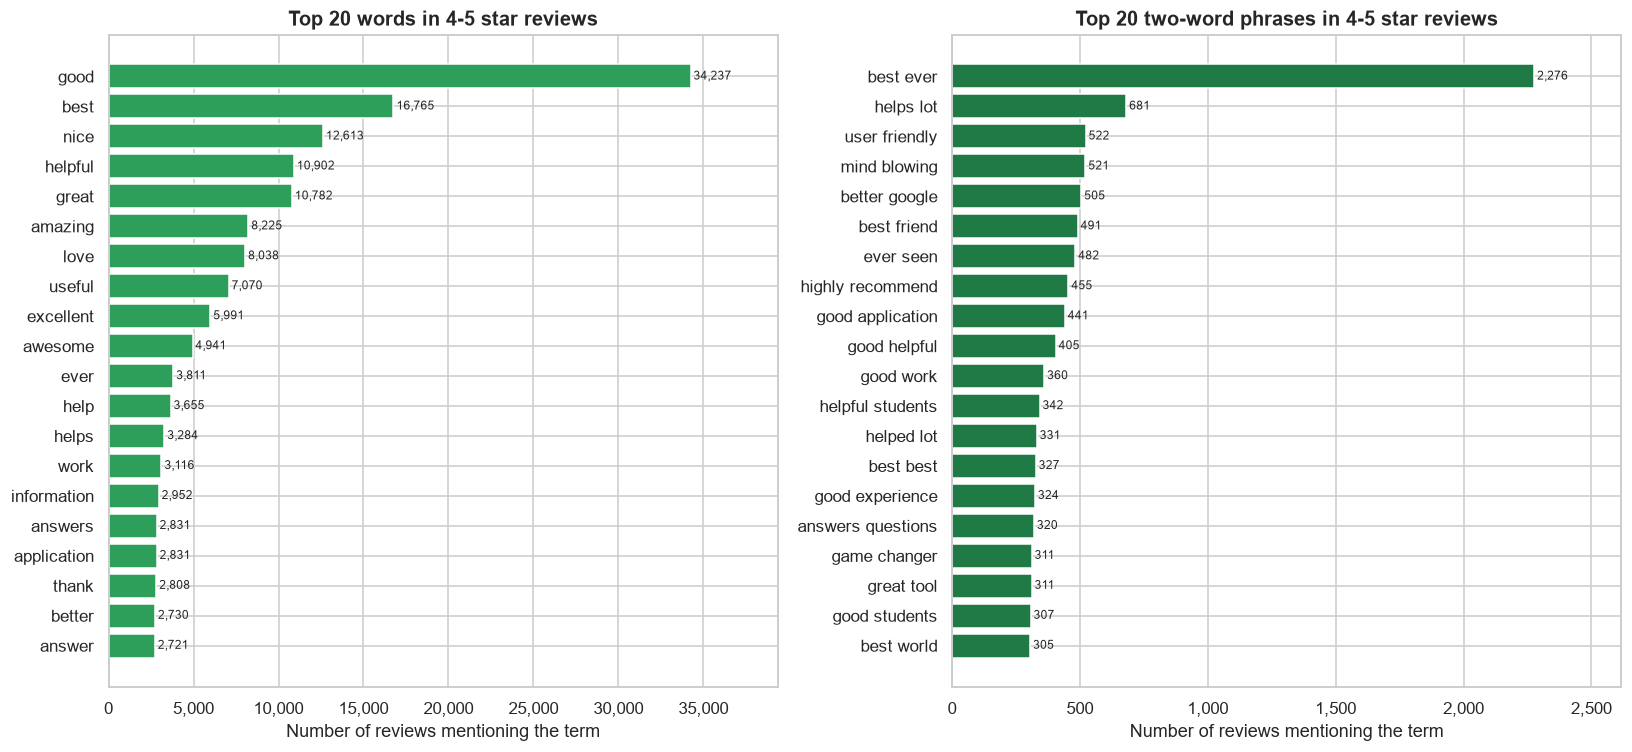

In [22]:
def bar_terms(ax, table, title, color):
    t = table.head(TOP_N).iloc[::-1]
    ax.barh(t["term"], t["reviews"], color=color)
    for y, v in enumerate(t["reviews"]):
        ax.text(v, y, f" {v:,}", va="center", fontsize=8)
    ax.set_title(title); ax.set_xlabel("Number of reviews mentioning the term")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_xlim(0, t["reviews"].max() * 1.15)


fig, ax = plt.subplots(1, 2, figsize=(15, 7))
bar_terms(ax[0], pos_words, f"Top {TOP_N} words in 4-5 star reviews", SENT_COLORS["Positive"])
bar_terms(ax[1], pos_bigrams, f"Top {TOP_N} two-word phrases in 4-5 star reviews", "#1F7A45")
plt.tight_layout()
plt.show()

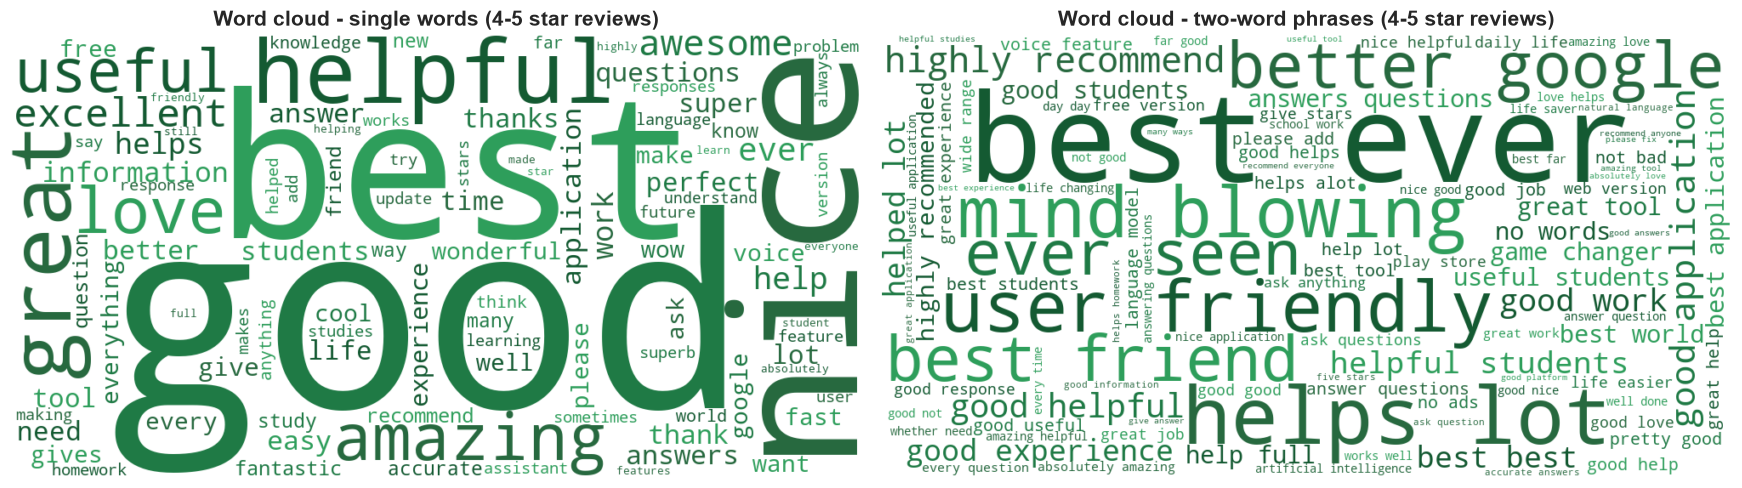

In [23]:
GREENS = ["#145A32", "#1F7A45", "#2E9E5B", "#27693F"]     # dark shades so small words stay readable
REDS = ["#7B1F1F", "#A32D2D", "#D64545", "#B03A2E"]


def draw_cloud(ax, table, title, shades):
    """Word cloud sized by frequency; colours picked from a dark palette (default colormaps fade to near-white)."""
    freq = dict(zip(table["term"], table["reviews"]))
    pick = lambda *args, **kwargs: shades[sum(map(ord, args[0])) % len(shades)]
    wc = WordCloud(width=1000, height=520, background_color="white", color_func=pick,
                   max_words=100, random_state=SEED).generate_from_frequencies(freq)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(title, fontsize=14)


fig, ax = plt.subplots(1, 2, figsize=(16, 5))
draw_cloud(ax[0], pos_words, "Word cloud - single words (4-5 star reviews)", GREENS)
draw_cloud(ax[1], pos_bigrams, "Word cloud - two-word phrases (4-5 star reviews)", GREENS)
plt.tight_layout()
plt.show()

### 👀 What we see
* The single words are mostly **general superlatives**: *good, best, nice, helpful, great, amazing, love, useful*. The phrases add the specifics:
  * **Superlatives & recommendation:** *best ever, mind blowing, game changer, highly recommend*.
  * **Usefulness:** *helps a lot, helpful students, good helpful, answers questions*.
  * **Ease of use:** *user friendly*.
  * **Comparison / companionship:** *better google, best friend* — some users see ChatGPT as a better search engine, others as a companion.
* Users thank ChatGPT for **what it does for them** (information, help with study, answers) rather than for the design of the app.
* 📌 **Marketing takeaway:** the most natural copy is "*helpful, user friendly, the best for answers and learning*" — in the users' own words.

## 7.3 Critical keywords & phrases (what to fix)
**Why:** The brief asks for the features users *praise or criticise*. The same technique on the 1–2★ reviews points to the pain points.

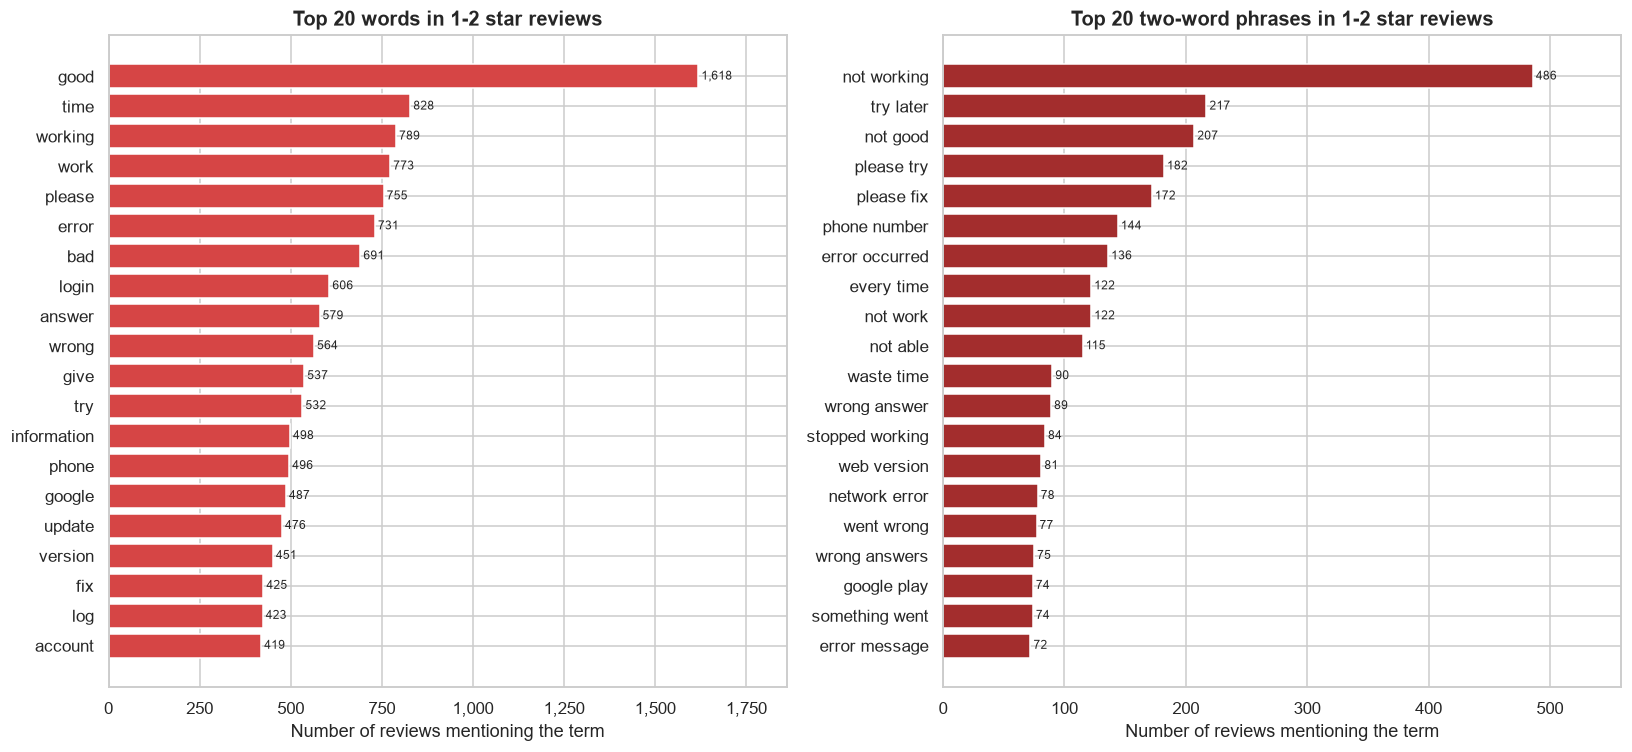

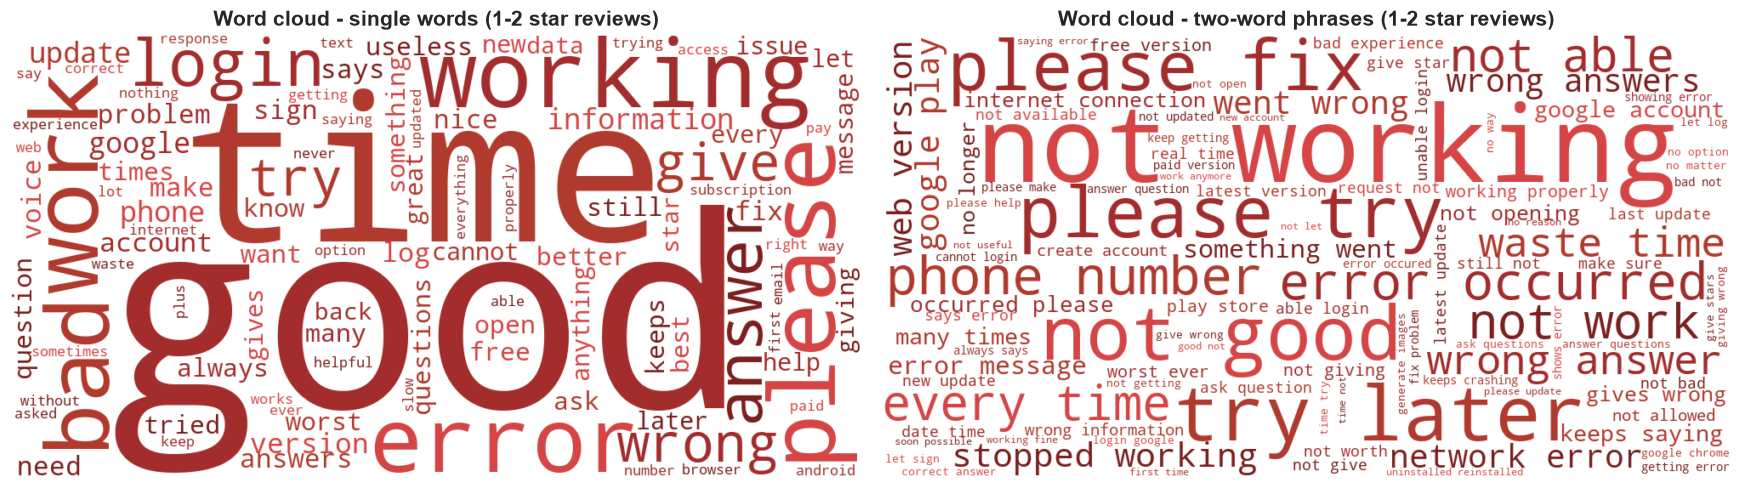

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
bar_terms(ax[0], neg_words, f"Top {TOP_N} words in 1-2 star reviews", SENT_COLORS["Negative"])
bar_terms(ax[1], neg_bigrams, f"Top {TOP_N} two-word phrases in 1-2 star reviews", "#A32D2D")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
draw_cloud(ax[0], neg_words, "Word cloud - single words (1-2 star reviews)", REDS)
draw_cloud(ax[1], neg_bigrams, "Word cloud - two-word phrases (1-2 star reviews)", REDS)
plt.tight_layout()
plt.show()

### 👀 What we see
The phrases fall into clear themes:
* **Errors / reliability (the loudest):** *not working, stopped working, try later, please try (again later), error occurred, network error, something went wrong, error message*, plus the plea *please fix*.
* **Access / login:** *phone number, login, log, account, google play, update, version, web version* — signing in, verification and app-version problems.
* **Answer quality (secondary):** *wrong answer(s), wrong, information*.
* **Wasted effort:** *waste time, every time*.

⚠️ **Why is "good" the top critical word?** Two reasons: negation (*"not good"* is the #3 phrase — we removed *not* from the single-word list) and probable mis-taps (*"good"* with 1★, seen in Section 6.5). It is a good reminder that star-based filters are not perfect.
Pricing / paywall words do not reach the top 20, but the aspect table below shows they are mentioned in about 8% of critical reviews (vs. ~1% of positive ones).

This **largely supports H2**: complaints are mainly about *getting to and staying on* ChatGPT (errors, login), with answer accuracy a smaller second theme. The next section turns these themes into hard numbers.

## 7.4 Aspect analysis – which features are mentioned, by happy vs. unhappy users?
**Why:** Word lists are suggestive; an *aspect table* is evidence. We define a handful of product themes with keyword patterns and measure **what % of positive and of critical reviews mention each**.
A big gap between the two bars means the aspect separates happy from unhappy users.

> 🔎 Patterns are deliberately simple regular expressions so they can be explained on camera. They are a *screening* tool, not a precise classifier.

,aspect,pct_positive_reviews,pct_critical_reviews,gap_(critical-positive)
0,Helpfulness & learning,16.4,5.7,-10.7
1,Ease of use / interface,2.8,1.6,-1.2
2,Coding & work,1.4,2.8,1.4
3,Speed & performance,2.3,4.2,2.0
4,Voice / image features,2.8,7.5,4.7
5,"Pricing, limits & paywall",1.4,8.0,6.6
6,Answer quality / accuracy,7.0,14.4,7.4
7,Login / verification,0.3,11.1,10.8
8,Errors & reliability,2.2,18.4,16.2


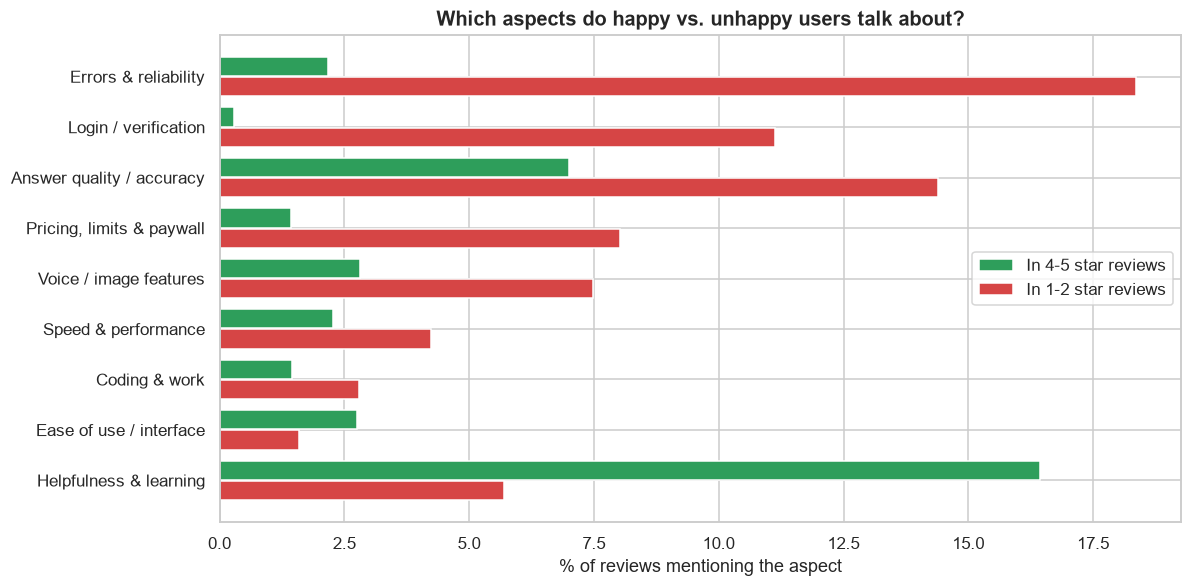

In [25]:
ASPECTS = {
    "Answer quality / accuracy":  r"answer|accura|correct|wrong|response|information",
    "Helpfulness & learning":     r"help|learn|stud|homework|school|student|knowledge|education",
    "Coding & work":              r"\bcod(e|ing|er)\b|program|developer|essay|writing",
    "Ease of use / interface":    r"easy|simple|user friendly|interface|convenient|smooth",
    "Speed & performance":        r"\bfast\b|quick|\bslow\b|speed|lag|loading|\bwait",
    "Errors & reliability":       r"error|\bbug|crash|glitch|fail|not working|doesnt work|network|server|problem|issue|stuck|stop",
    "Login / verification":       r"login|log in|sign in|signin|account|verif|phone number|\botp\b|captcha|\bcode\b.*sent|register",
    "Pricing, limits & paywall":  r"\bpay|paid|premium|subscri|price|upgrade|limit|\bplus\b|money|cost",
    "Voice / image features":     r"voice|speech|speak|audio|image|photo|picture",
}

rows = []
for name, pattern in ASPECTS.items():
    pos_share = positive_df["clean_review"].str.contains(pattern, regex=True).mean() * 100
    neg_share = critical_df["clean_review"].str.contains(pattern, regex=True).mean() * 100
    rows.append({"aspect": name, "pct_positive_reviews": pos_share, "pct_critical_reviews": neg_share,
                 "gap_(critical-positive)": neg_share - pos_share})
aspects = pd.DataFrame(rows).sort_values("gap_(critical-positive)").reset_index(drop=True)
display(aspects.round(1))

fig, ax = plt.subplots(figsize=(11, 5.5))
y = np.arange(len(aspects))
ax.barh(y + 0.2, aspects["pct_positive_reviews"], height=0.38, color=SENT_COLORS["Positive"], label="In 4-5 star reviews")
ax.barh(y - 0.2, aspects["pct_critical_reviews"], height=0.38, color=SENT_COLORS["Negative"], label="In 1-2 star reviews")
ax.set_yticks(y); ax.set_yticklabels(aspects["aspect"])
ax.set_xlabel("% of reviews mentioning the aspect"); ax.legend(loc="center right")
ax.set_title("Which aspects do happy vs. unhappy users talk about?")
plt.tight_layout()
plt.show()

### 👀 What we see
* Aspects whose **critical bar is much longer** than the positive bar are the real **pain points** — these are the ones to fix first.
* Aspects where the **positive bar is longer** are the **strengths** to protect and advertise.
* Aspects with similar bars are mentioned by everyone and do not discriminate between happy and unhappy users.

(The exact numbers are pulled into the summary in the next section, so the story always matches the data.)

---
# 8️⃣ Insights, Recommendations & Next Steps

## 8.1 Key numbers (computed live from the data)

In [26]:
pos_share = (df["sentiment"] == "Positive").mean() * 100
neg_share = (df["sentiment"] == "Negative").mean() * 100
neu_share = (df["sentiment"] == "Neutral").mean() * 100
five_star = (df["rating"] == 5).mean() * 100
one_star = (df["rating"] == 1).mean() * 100
opinion_words = df[df["subjectivity"] > 0]
top_pain = aspects.sort_values("gap_(critical-positive)", ascending=False).head(3)
top_strength = aspects[aspects["gap_(critical-positive)"] < -2].sort_values("gap_(critical-positive)").head(3)

summary = f"""
| Metric | Value |
|---|---|
| Reviews analysed | **{len(df):,}** ({df['review_date'].min():%b %Y} - {df['review_date'].max():%b %Y}) |
| Average rating | **{df['rating'].mean():.2f} / 5** ({five_star:.0f}% are 5-star, {one_star:.0f}% are 1-star) |
| Sentiment split | **{pos_share:.0f}% Positive**, {neu_share:.0f}% Neutral, **{neg_share:.0f}% Negative** |
| Mean polarity | **{df['polarity'].mean():+.2f}** (scale -1 to +1) |
| Mean subjectivity (reviews with opinion words) | **{opinion_words['subjectivity'].mean():.2f}** (scale 0 to 1) |
| Rating-vs-polarity correlation (Spearman) | **{corr:.2f}** |
| 1-2 star reviews with clearly positive wording | **{len(low_but_positive)/n_low:.1%}** |
| Top praised words | {", ".join(pos_words['term'].head(6))} |
| Top praised phrases | {", ".join(pos_bigrams['term'].head(4))} |
| Top criticised words | {", ".join(neg_words['term'].head(6))} |
| Top criticised phrases | {", ".join(neg_bigrams['term'].head(4))} |
| Biggest pain-point aspects (critical vs. positive) | {", ".join(f"{r['aspect']} (+{r['gap_(critical-positive)']:.0f} pts)" for r in top_pain.to_dict("records"))} |
| Strength aspects (mentioned more by happy users) | {", ".join(f"{r['aspect']} (+{-r['gap_(critical-positive)']:.0f} pts)" for r in top_strength.to_dict("records"))} |
"""
display(Markdown(summary))


| Metric | Value |
|---|---|
| Reviews analysed | **193,148** (Jul 2023 - Aug 2024) |
| Average rating | **4.51 / 5** (77% are 5-star, 6% are 1-star) |
| Sentiment split | **76% Positive**, 21% Neutral, **4% Negative** |
| Mean polarity | **+0.45** (scale -1 to +1) |
| Mean subjectivity (reviews with opinion words) | **0.65** (scale 0 to 1) |
| Rating-vs-polarity correlation (Spearman) | **0.25** |
| 1-2 star reviews with clearly positive wording | **13.1%** |
| Top praised words | good, best, nice, helpful, great, amazing |
| Top praised phrases | best ever, helps lot, user friendly, mind blowing |
| Top criticised words | good, time, working, work, please, error |
| Top criticised phrases | not working, try later, not good, please try |
| Biggest pain-point aspects (critical vs. positive) | Errors & reliability (+16 pts), Login / verification (+11 pts), Answer quality / accuracy (+7 pts) |
| Strength aspects (mentioned more by happy users) | Helpfulness & learning (+11 pts) |


## 8.2 Answers to the business question

| Question | Answer |
|----------|--------|
| **Q1 – General sentiment?** | Strongly **positive**. Most reviews are positive in both stars and text; negative reviews are a small minority and stable over time. |
| **Q2 – Strength of sentiment?** | Reviews are **opinionated**, not factual — in both directions. Users who feel something say so emphatically. |
| **Q3 – What is praised / criticised?** | **Praised:** being *good / best / helpful*, and above all **helping and learning** (the clearest strength in the aspect table). **Criticised:** **reliability** (errors, "not working", "try again later"), **access** (login, phone-number verification), **limits / paywall**, and — as a secondary theme — **answer accuracy**. |

| Hypothesis | Verdict |
|------------|---------|
| **H1** Stars and text sentiment agree | ✅ Supported in direction – mean polarity rises with every star – but the link is **weak** (Spearman ≈ 0.25). |
| **H2** Praise = what it does; criticism = access & reliability | ✅ Largely supported – errors and login are the biggest gaps; answer accuracy is a real but secondary complaint. |
| **H3** Some reviews contradict their own stars | ✅ Supported – a small share of 1–2★ reviews use positive wording. |

## 8.3 Recommendations
1. **Fix reliability first.** "Errors / not working / network" is the loudest complaint among unhappy users. A visible status indicator, clearer error messages, and retry / resume-on-failure (answers that stop midway) would address the top pain point directly.
2. **Reduce sign-in friction.** Login and phone-verification issues appear far more in critical than in positive reviews. Offer alternative sign-in options and clearer verification guidance.
3. **Make limits and pricing transparent.** Complaints about being asked to upgrade or hitting limits are a distinct theme; communicate limits *before* users hit them.
4. **Keep improving answer accuracy.** Wrong or inaccurate answers appear in roughly 1 in 7 critical reviews (twice the rate seen in positive reviews). Visible source links or "double-check this" cues could help.
5. **Protect what works.** Helpfulness and learning/study use are the clearest strengths. Reuse *helpful, user friendly, best for students* in app-store copy and onboarding.
6. **Don't rely on stars alone.** Triage 1–2★ reviews by *text theme* (support routing), and flag stars/text mismatches as probable mis-taps before they drag down reported averages.

## 8.4 Limitations (be honest about these)
* **TextBlob is lexicon-based.** It misses sarcasm, slang and context, and most reviews are very short (median = 4 words) → about 1 in 5 score exactly 0. The weak rating-vs-polarity link (≈ 0.25) shows the text score is noisy.
* **English only.** Non-English and emoji-only reviews are mostly scored Neutral (shown in 6.5) — the Neutral share is inflated.
* **Keyword patterns are simple.** Aspect counts are indicative, not exact; a word like *"problem"* can appear in a positive context ("solves problems"). Also, most critical reviews are only a few words long, so the majority mention **no identifiable aspect at all** — the percentages are a lower bound.
* **Correlation, not causation.** We describe what users mention, not why ratings changed.
* **One platform and ~13 months.** Findings are for Google Play between Jul 2023 and Aug 2024.

## 8.5 Ideas for further analysis
* Compare with a **transformer model** (e.g. a multilingual BERT/RoBERTa sentiment model) and measure agreement with TextBlob.
* Detect language first (e.g. `langdetect`) and analyse non-English reviews separately.
* Run **topic modelling (LDA / BERTopic)** on 1–2★ reviews to discover complaint themes automatically instead of predefined aspects.
* Link review spikes to **product release dates** to see which launches helped or hurt satisfaction.
* Build a simple **review-routing classifier** (bug / billing / login / praise) for the support team.

---
# 9️⃣ Conclusion & Appendix

**In one sentence:** Users overwhelmingly like what ChatGPT *does* — it is helpful and good for learning — and the dissatisfaction that exists is mostly about *reliability, access and limits*, with answer accuracy a smaller secondary theme.

## Save the cleaned & scored dataset
So the results can be reused (e.g. in Excel / Tableau / Power BI) without re-running the NLP.

In [27]:
OUTPUT_FILE = "chatgpt_reviews_scored.csv"
export_cols = ["review_id", "review", "rating", "review_date", "word_count", "polarity", "subjectivity", "sentiment"]
df[export_cols].to_csv(OUTPUT_FILE, index=False)
print(f"Saved {len(df):,} rows -> {OUTPUT_FILE}")
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(OUTPUT_FILE)           # optional: download from Colab to your computer

Saved 193,148 rows -> chatgpt_reviews_scored.csv


In [28]:
# Reproducibility: library versions used for this run
import textblob, sklearn, wordcloud, matplotlib
print({"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
       "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
       "seaborn": sns.__version__, "nltk": nltk.__version__, "wordcloud": wordcloud.__version__})

{'python': '3.12.7', 'pandas': '3.0.5', 'numpy': '1.26.4', 'scikit-learn': '1.9.0', 'matplotlib': '3.11.1', 'seaborn': '0.13.2', 'nltk': '3.10.3', 'wordcloud': '1.9.6'}
